# Lab 1 — Sentiment Analysis Using Traditional Machine Learning
**PUSL 3205 — Large Language Models and Generative AI**

In this lab I build a sentiment classifier using *traditional* NLP + machine learning
(no neural networks): text preprocessing → Bag-of-Words features → Logistic Regression
and Linear SVM. I follow the lab sheet task list end to end:

1. Download and load the dataset
2. Basic text preprocessing (lowercase, strip punctuation, collapse whitespace, clean-text column, before/after)
3. Explore the text data (positive/negative examples, frequent words, differences)
4. Split the dataset
5. Create a Bag-of-Words representation
6. Train ML models (Logistic Regression **and** Linear SVM, so I can compare)
7. Evaluate (Accuracy, Precision, Recall, F1)
8. Test the model on new sentences

**Dataset:** UCI *Sentiment Labelled Sentences* (Amazon, IMDb, Yelp) —
https://archive.ics.uci.edu/dataset/331/sentiment+labelled+sentences

In [1]:
# Imports
import os, re, io, ssl, zipfile, urllib.request, functools
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

import nltk

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
os.makedirs("outputs", exist_ok=True)
RANDOM_STATE = 42
print("Setup complete. Outputs will be saved to ./outputs/")

Setup complete. Outputs will be saved to ./outputs/


## 1. Download and load the dataset

The UCI archive ships the data as a zip of three tab-separated files — `amazon_cells_labelled.txt`,
`imdb_labelled.txt`, and `yelp_labelled.txt` — each line being `sentence<TAB>label` with
`label` = 1 (positive) or 0 (negative).

I download it **programmatically**. The Python.org build on this machine doesn't carry a system CA
bundle, so I point SSL at `certifi`'s bundle — that keeps certificate verification *on* (safer than
disabling it) and also fixes `nltk.download` further down.

In [2]:
# Use certifi's CA bundle for all HTTPS (fixes 'CERTIFICATE_VERIFY_FAILED' on this Python build)
import certifi
ssl._create_default_https_context = functools.partial(ssl.create_default_context, cafile=certifi.where())

URL = "https://archive.ics.uci.edu/static/public/331/sentiment+labelled+sentences.zip"
FILES = {
    "amazon": "sentiment labelled sentences/amazon_cells_labelled.txt",
    "imdb":   "sentiment labelled sentences/imdb_labelled.txt",
    "yelp":   "sentiment labelled sentences/yelp_labelled.txt",
}

req = urllib.request.Request(URL, headers={"User-Agent": "Mozilla/5.0"})
try:
    raw_zip = urllib.request.urlopen(req, timeout=60).read()
except Exception as e:
    raise SystemExit(f"Dataset download FAILED ({type(e).__name__}: {e}). "
                     f"Stopping rather than fabricating data.")
print(f"Downloaded {len(raw_zip):,} bytes")

zf = zipfile.ZipFile(io.BytesIO(raw_zip))
frames = []
for source, path in FILES.items():
    text = zf.read(path).decode("utf-8", "replace")
    rows = [ln.rsplit("\t", 1) for ln in text.splitlines() if "\t" in ln]
    df_src = pd.DataFrame(rows, columns=["text", "label"])
    df_src["label"] = df_src["label"].astype(int)
    df_src["source"] = source
    frames.append(df_src)

df = pd.concat(frames, ignore_index=True)
print(f"Loaded {len(df)} labelled sentences from {df['source'].nunique()} sources")
df.head()

Downloaded 84,188 bytes
Loaded 3000 labelled sentences from 3 sources


,text,label,source
0,So there is no way for me to plug it in here i...,0,amazon
1,"Good case, Excellent value.",1,amazon
2,Great for the jawbone.,1,amazon
3,Tied to charger for conversations lasting more...,0,amazon
4,The mic is great.,1,amazon


In [3]:
# Shape, balance and a peek per source
print("Rows per source:")
print(df["source"].value_counts(), "\n")
print("Label balance (1 = positive, 0 = negative):")
print(df["label"].value_counts(), "\n")
df.groupby("source")["label"].mean().rename("positive_fraction")

Rows per source:
source
amazon    1000
imdb      1000
yelp      1000
Name: count, dtype: int64 

Label balance (1 = positive, 0 = negative):
label
0    1500
1    1500
Name: count, dtype: int64 



source
amazon    0.5
imdb      0.5
yelp      0.5
Name: positive_fraction, dtype: float64

## 2. Basic text preprocessing

The cleaning steps from the lab sheet: lowercase, remove punctuation / non-letter characters,
collapse extra whitespace, and store the result in a new `clean_text` column so I can compare
before and after.

In [4]:
def clean_text(text: str) -> str:
    text = text.lower()                      # 1. lowercase
    text = re.sub(r"[^a-z\s]", " ", text)    # 2. remove punctuation / digits / symbols
    text = re.sub(r"\s+", " ", text).strip() # 3. collapse extra whitespace
    return text

df["clean_text"] = df["text"].apply(clean_text)

# Compare original vs preprocessed
compare = df[["text", "clean_text"]].head(6).copy()
compare

,text,clean_text
0,So there is no way for me to plug it in here i...,so there is no way for me to plug it in here i...
1,"Good case, Excellent value.",good case excellent value
2,Great for the jawbone.,great for the jawbone
3,Tied to charger for conversations lasting more...,tied to charger for conversations lasting more...
4,The mic is great.,the mic is great
5,I have to jiggle the plug to get it to line up...,i have to jiggle the plug to get it to line up...


In [5]:
# A clearer before/after view for a few rows
for _, row in df.sample(4, random_state=RANDOM_STATE).iterrows():
    print("ORIGINAL :", row["text"])
    print("CLEANED  :", row["clean_text"])
    print("-" * 70)

ORIGINAL : Avoid at ALL costs!  
CLEANED  : avoid at all costs
----------------------------------------------------------------------
ORIGINAL : Garbo, who showed right off the bat that her talents could carry over from the silent era (I wanted to see some of her silent work, but Netflix doesn't seem to be stocking them.  
CLEANED  : garbo who showed right off the bat that her talents could carry over from the silent era i wanted to see some of her silent work but netflix doesn t seem to be stocking them
----------------------------------------------------------------------
ORIGINAL : You will leave the theater wanting to go out and dance under the stars.  
CLEANED  : you will leave the theater wanting to go out and dance under the stars
----------------------------------------------------------------------
ORIGINAL : O my gosh the best phone I have ever had.
CLEANED  : o my gosh the best phone i have ever had
----------------------------------------------------------------------


## 3. Explore the text data (EDA)

Here I look at positive vs negative examples, the most frequent words in each class, and how the
two classes differ. I use NLTK's English stop-word list so the frequency charts aren't dominated by
words like *the*, *and*, *a*.

In [6]:
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords
STOP = set(stopwords.words("english"))

print("Example POSITIVE reviews:")
for t in df[df.label == 1]["text"].sample(3, random_state=1): print("  +", t)
print("\nExample NEGATIVE reviews:")
for t in df[df.label == 0]["text"].sample(3, random_state=1): print("  -", t)

Example POSITIVE reviews:
  + The file browser offers all the options that one needs.Handsfree is great.
  + My headset works just peachy-keen.
  + We enjoy their pizza and brunch.

Example NEGATIVE reviews:
  - Waste of 13 bucks.
  - All I can do is whine on the Internet, so here it goes.The more I use the thing the less I like it.
  - Not good for the money.


/var/folders/95/vxn9r4wx61b3rh2y8v8fy3jw0000gn/T/ipykernel_2991/2012846468.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="label", order=order, ax=axes[0], palette=["#e05a47", "#3aa86b"])
/var/folders/95/vxn9r4wx61b3rh2y8v8fy3jw0000gn/T/ipykernel_2991/2012846468.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(["negative (0)", "positive (1)"])


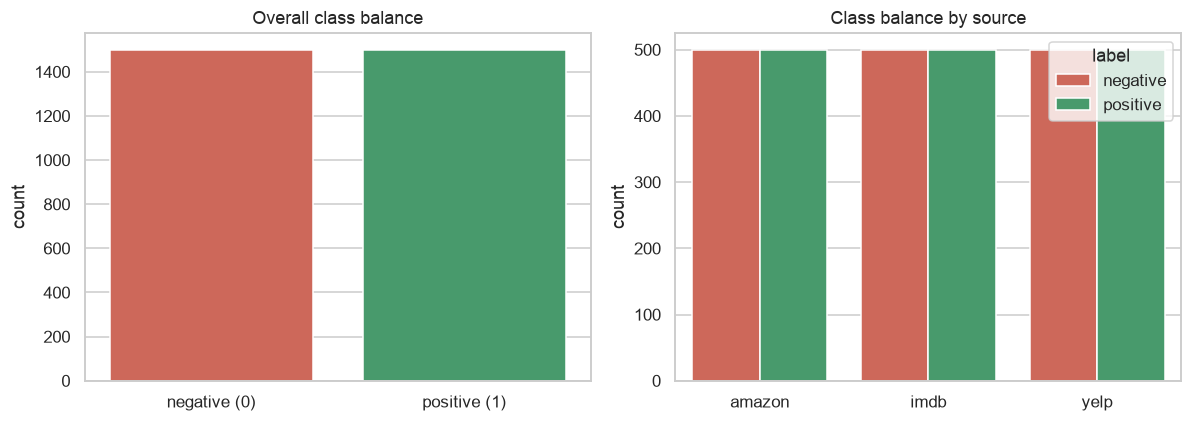

In [7]:
# Class distribution plot (overall + by source) -> saved PNG
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

order = [0, 1]
sns.countplot(data=df, x="label", order=order, ax=axes[0], palette=["#e05a47", "#3aa86b"])
axes[0].set_title("Overall class balance")
axes[0].set_xticklabels(["negative (0)", "positive (1)"])
axes[0].set_xlabel(""); axes[0].set_ylabel("count")

sns.countplot(data=df, x="source", hue="label", ax=axes[1], palette=["#e05a47", "#3aa86b"])
axes[1].set_title("Class balance by source")
axes[1].set_xlabel(""); axes[1].set_ylabel("count")
axes[1].legend(title="label", labels=["negative", "positive"])

plt.tight_layout()
plt.savefig("outputs/class_distribution.png", bbox_inches="tight")
plt.show()

Top positive words: [('great', 201), ('good', 178), ('film', 105), ('phone', 88), ('movie', 86), ('one', 76), ('well', 68), ('best', 63), ('food', 60), ('place', 58)]
Top negative words: [('bad', 100), ('movie', 96), ('phone', 80), ('one', 70), ('like', 69), ('food', 66), ('time', 62), ('would', 59), ('film', 58), ('place', 56)]


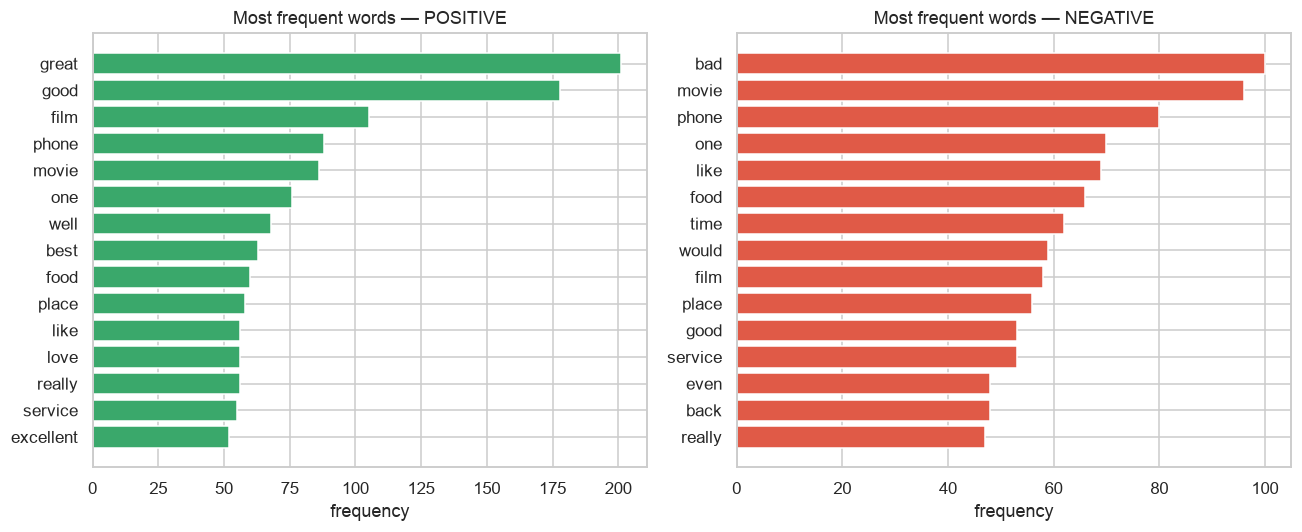

In [8]:
# Frequent words per class (stop-words removed)
def top_words(texts, n=15):
    counter = Counter()
    for t in texts:
        counter.update(w for w in t.split() if w not in STOP and len(w) > 2)
    return counter.most_common(n)

pos_words = top_words(df[df.label == 1]["clean_text"])
neg_words = top_words(df[df.label == 0]["clean_text"])

print("Top positive words:", pos_words[:10])
print("Top negative words:", neg_words[:10])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, words, title, color in [
    (axes[0], pos_words, "Most frequent words — POSITIVE", "#3aa86b"),
    (axes[1], neg_words, "Most frequent words — NEGATIVE", "#e05a47"),
]:
    labels = [w for w, _ in words][::-1]
    counts = [c for _, c in words][::-1]
    ax.barh(labels, counts, color=color)
    ax.set_title(title)
    ax.set_xlabel("frequency")

plt.tight_layout()
plt.savefig("outputs/top_words_by_class.png", bbox_inches="tight")
plt.show()

In [9]:
# Observation: words that lean strongly positive vs negative
pos_set = dict(top_words(df[df.label == 1]["clean_text"], n=40))
neg_set = dict(top_words(df[df.label == 0]["clean_text"], n=40))
distinct_pos = sorted(set(pos_set) - set(neg_set))
distinct_neg = sorted(set(neg_set) - set(pos_set))
print("Common in POSITIVE but not top-NEGATIVE:", distinct_pos)
print("\nCommon in NEGATIVE but not top-POSITIVE:", distinct_neg)

Common in POSITIVE but not top-NEGATIVE: ['amazing', 'best', 'every', 'everything', 'excellent', 'friendly', 'great', 'headset', 'love', 'nice', 'pretty', 'price', 'product', 'recommend', 'see', 'sound', 'think', 'wonderful', 'works']

Common in NEGATIVE but not top-POSITIVE: ['acting', 'bad', 'battery', 'could', 'disappointed', 'first', 'get', 'got', 'make', 'minutes', 'money', 'much', 'never', 'poor', 'terrible', 'waste', 'way', 'work', 'worst']


## 4. Split the dataset

An 80/20 stratified train/test split, so the positive/negative balance is preserved in both sets.

In [10]:
X = df["clean_text"]
y = df["label"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
print(f"Train: {len(X_train)}  |  Test: {len(X_test)}")
print("Train balance:", y_train.value_counts(normalize=True).round(3).to_dict())
print("Test balance :", y_test.value_counts(normalize=True).round(3).to_dict())

Train: 2400  |  Test: 600
Train balance: {1: 0.5, 0: 0.5}
Test balance : {1: 0.5, 0: 0.5}


## 5. Create a Bag-of-Words (BOW) representation

I fit a `CountVectorizer` **on the training set only** (then just transform the test set) to avoid
leaking test vocabulary into training. BOW represents each sentence as a vector of word counts over
the learned vocabulary. I drop terms that appear only once (`min_df=2`) to cut noise.

In [11]:
bow = CountVectorizer(min_df=2)
X_train_bow = bow.fit_transform(X_train)
X_test_bow = bow.transform(X_test)
print(f"BOW matrix: {X_train_bow.shape[0]} docs x {X_train_bow.shape[1]} vocabulary terms")
print("A few vocabulary terms:", list(bow.get_feature_names_out()[500:510]))

BOW matrix: 2400 docs x 1878 vocabulary terms
A few vocabulary terms: ['easily', 'easy', 'eat', 'eaten', 'eating', 'echo', 'edge', 'editing', 'effect', 'effective']


## 6. Train ML models — Logistic Regression and Linear SVM

I train two linear classifiers on the same BOW features so I can compare them directly.

In [12]:
logreg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
logreg.fit(X_train_bow, y_train)

svm = LinearSVC(random_state=RANDOM_STATE)
svm.fit(X_train_bow, y_train)
print("Both models trained on BOW features.")

Both models trained on BOW features.


## 7. Evaluate (Accuracy, Precision, Recall, F1)

In [13]:
def evaluate(model, name):
    pred = model.predict(X_test_bow)
    metrics = {
        "model": name,
        "accuracy":  accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "recall":    recall_score(y_test, pred),
        "f1":        f1_score(y_test, pred),
    }
    print(f"\n=== {name} ===")
    print(classification_report(y_test, pred, target_names=["negative", "positive"]))
    return metrics, pred

m_lr, pred_lr = evaluate(logreg, "Logistic Regression")
m_svm, pred_svm = evaluate(svm, "Linear SVM")

results = pd.DataFrame([m_lr, m_svm]).set_index("model").round(4)
results


=== Logistic Regression ===
              precision    recall  f1-score   support

    negative       0.84      0.79      0.81       300
    positive       0.80      0.85      0.82       300

    accuracy                           0.82       600
   macro avg       0.82      0.82      0.82       600
weighted avg       0.82      0.82      0.82       600


=== Linear SVM ===
              precision    recall  f1-score   support

    negative       0.82      0.74      0.78       300
    positive       0.76      0.84      0.80       300

    accuracy                           0.79       600
   macro avg       0.79      0.79      0.79       600
weighted avg       0.79      0.79      0.79       600



,accuracy,precision,recall,f1
model,,,,
Logistic Regression,0.8167,0.7987,0.8467,0.8220
Linear SVM,0.7883,0.7629,0.8367,0.7981


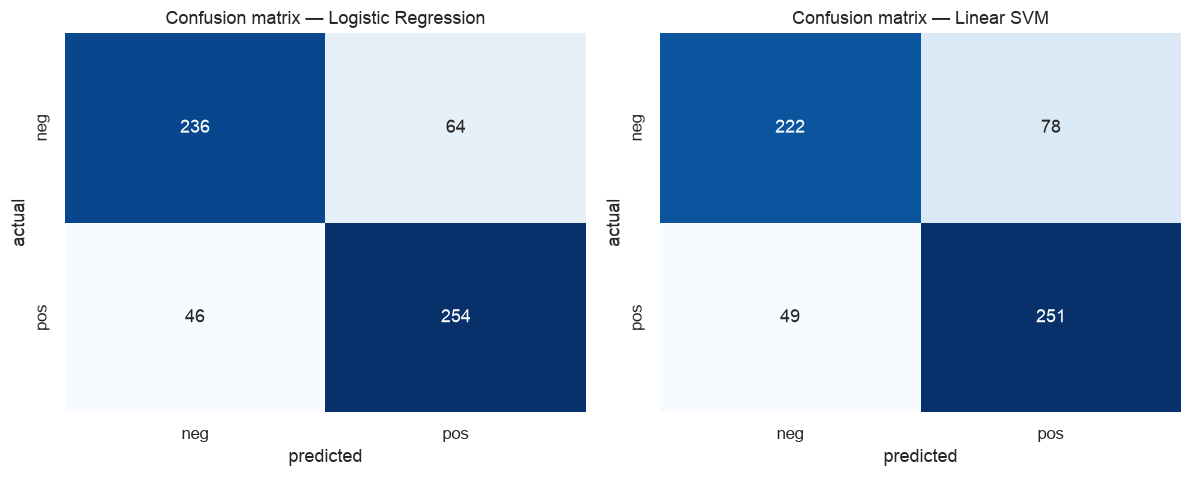

In [14]:
# Confusion matrices side by side -> saved PNG
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, pred, name in [(axes[0], pred_lr, "Logistic Regression"),
                       (axes[1], pred_svm, "Linear SVM")]:
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["neg", "pos"], yticklabels=["neg", "pos"])
    ax.set_title(f"Confusion matrix — {name}")
    ax.set_xlabel("predicted"); ax.set_ylabel("actual")
plt.tight_layout()
plt.savefig("outputs/confusion_matrices.png", bbox_inches="tight")
plt.show()

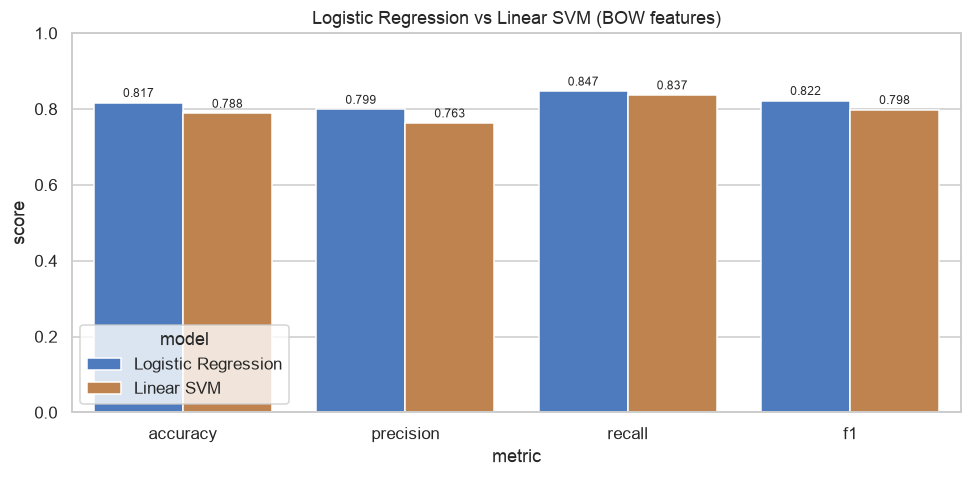

In [15]:
# Metric comparison bar chart -> saved PNG
plot_df = results.reset_index().melt(id_vars="model", var_name="metric", value_name="score")
plt.figure(figsize=(9, 4.5))
ax = sns.barplot(data=plot_df, x="metric", y="score", hue="model",
                 palette=["#3b76d1", "#d1823b"])
ax.set_ylim(0.0, 1.0)
ax.set_title("Logistic Regression vs Linear SVM (BOW features)")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)
plt.tight_layout()
plt.savefig("outputs/model_comparison.png", bbox_inches="tight")
plt.show()

### Bonus: does TF-IDF help?

The lab sheet asks for BOW, but TF-IDF is the natural comparison — it down-weights words that appear
in almost every review (so informative but rarer words count for more). I refit both classifiers on
TF-IDF features to see whether it moves the F1 at all.

In [16]:
tfidf = TfidfVectorizer(min_df=2)
Xtr_tfidf = tfidf.fit_transform(X_train)
Xte_tfidf = tfidf.transform(X_test)

rows = []
for name, model in [("Logistic Regression", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
                    ("Linear SVM", LinearSVC(random_state=RANDOM_STATE))]:
    model.fit(Xtr_tfidf, y_train)
    p = model.predict(Xte_tfidf)
    rows.append({"model": name, "features": "TF-IDF",
                 "accuracy": accuracy_score(y_test, p), "f1": f1_score(y_test, p)})

bow_rows = [{"model": n, "features": "BOW", "accuracy": m["accuracy"], "f1": m["f1"]}
            for n, m in [("Logistic Regression", m_lr), ("Linear SVM", m_svm)]]
pd.DataFrame(bow_rows + rows).set_index(["model", "features"]).round(4)

,,accuracy,f1
model,features,,
Logistic Regression,BOW,0.8167,0.8220
Linear SVM,BOW,0.7883,0.7981
Logistic Regression,TF-IDF,0.8333,0.8377
Linear SVM,TF-IDF,0.8217,0.8283


## 8. Test the model on new sentences

Finally I run a few hand-written sentences the models have never seen through the same cleaning +
BOW pipeline. I use Logistic Regression's `predict_proba` to show the confidence, alongside the
SVM's label.

In [17]:
new_sentences = [
    "This product is absolutely fantastic, I love it!",
    "Worst purchase I have ever made, totally useless.",
    "The food was delicious and the service was great.",
    "I would not recommend this to anyone, very disappointing.",
    "It works fine, nothing special but does the job.",
]

clean_new = [clean_text(s) for s in new_sentences]
vec_new = bow.transform(clean_new)

proba = logreg.predict_proba(vec_new)[:, 1]   # P(positive)
lr_pred = logreg.predict(vec_new)
svm_pred = svm.predict(vec_new)

label = {1: "POSITIVE", 0: "negative"}
out = pd.DataFrame({
    "sentence": new_sentences,
    "LogReg": [label[p] for p in lr_pred],
    "P(pos)": proba.round(3),
    "LinearSVM": [label[p] for p in svm_pred],
})
out

,sentence,LogReg,P(pos),LinearSVM
0,"This product is absolutely fantastic, I love it!",POSITIVE,0.979,POSITIVE
1,"Worst purchase I have ever made, totally useless.",negative,0.033,negative
2,The food was delicious and the service was great.,POSITIVE,0.986,POSITIVE
3,"I would not recommend this to anyone, very dis...",negative,0.027,negative
4,"It works fine, nothing special but does the job.",POSITIVE,0.965,POSITIVE


## Summary

- Built a full traditional-NLP sentiment pipeline on the UCI Amazon/IMDb/Yelp dataset.
- Cleaned text, explored class differences, and represented sentences as Bag-of-Words.
- Trained and compared **Logistic Regression** and **Linear SVM**, scoring Accuracy / Precision /
  Recall / F1, and checked TF-IDF as an alternative feature set.
- Confirmed the models generalise sensibly on fresh, hand-written sentences.

All plots are saved in `outputs/` and discussed in `REVIEW.md`.